# LAB CHƯƠNG 3 — CANNY EDGE DETECTOR

Notebook được sắp xếp theo đúng **4 yêu cầu thực hành** trong slide. Mỗi mục gồm: **mục đích → xử lý → hiển thị kết quả → chỉ số/biểu đồ → nhận xét ngắn**.

**Ảnh đầu vào:** đặt ảnh trong thư mục `input/` nằm cạnh notebook. Mặc định notebook dùng `anh_mau_lab3.png` để có thể chạy ngay; nếu có ảnh riêng, đổi `IMAGE_FILENAME` ở phần 1. Không tải ảnh từ Internet.

**Kết quả:** ảnh và bảng số liệu được lưu trong thư mục `results/`.

**Lưu ý:** các ảnh nhiễu, tương phản thấp và nhiều chi tiết ở phần III được tạo từ ảnh đầu vào để so sánh có kiểm soát.

## 0. Thư viện và thiết lập

Các thư viện chính: OpenCV và Scikit-image để phát hiện cạnh; NumPy để xử lý ma trận ảnh; Matplotlib để hiển thị; Pandas để tổng hợp số liệu.

In [1]:
# Nếu thiếu thư viện, bỏ dấu # và chạy lệnh sau:
# %pip install opencv-python numpy matplotlib scikit-image scipy pandas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
from pathlib import Path
from skimage import feature
from IPython.display import display

SEED = 42
np.random.seed(SEED)
INPUT_DIR = Path("input")
OUTPUT_DIR = Path("results")
INPUT_DIR.mkdir(exist_ok=True)
OUTPUT_DIR.mkdir(exist_ok=True)

print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Scikit-image:", __import__("skimage").__version__)

ModuleNotFoundError: No module named 'pandas'

## 1. Đọc ảnh do người dùng cung cấp

Đặt ảnh trong `input/`. Mặc định dùng `anh_mau_lab3.png` đi kèm gói Lab 3. Nếu muốn dùng ảnh riêng, đổi `IMAGE_FILENAME` thành tên file ảnh của bạn.

Ảnh: anh_mau_lab3.png | Kích thước: 560 x 560 | dtype: uint8


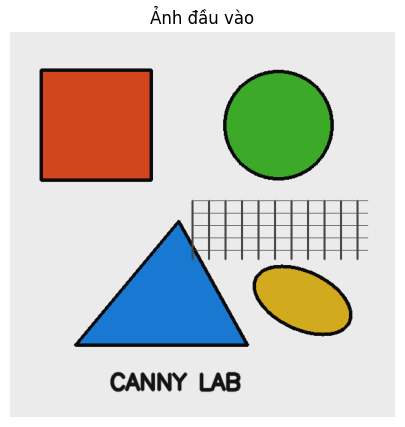

In [ ]:
IMAGE_FILENAME = "anh_mau_lab3.png"  # Ví dụ: "anh_cua_toi.jpg"

extensions = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".webp"}
image_files = sorted(p for p in INPUT_DIR.iterdir()
                     if p.is_file() and p.suffix.lower() in extensions)
if not image_files:
    raise FileNotFoundError("Thư mục input/ chưa có ảnh. Hãy chép ảnh vào đây.")

image_path = INPUT_DIR / IMAGE_FILENAME
if not image_path.is_file():
    if len(image_files) == 1:
        image_path = image_files[0]
        print("Không tìm thấy tên mặc định; tự chọn ảnh duy nhất:", image_path.name)
    else:
        raise FileNotFoundError(f"Không tìm thấy {IMAGE_FILENAME}. Hãy sửa IMAGE_FILENAME.")

image = cv2.imdecode(np.fromfile(str(image_path), dtype=np.uint8), cv2.IMREAD_COLOR)
if image is None:
    raise ValueError(f"Không đọc được ảnh: {image_path}")

# Giới hạn kích thước để notebook chạy ổn định trên máy cá nhân.
max_side = 800
h, w = image.shape[:2]
scale = min(1.0, max_side / max(h, w))
if scale < 1:
    image = cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
height, width = gray.shape
print(f"Ảnh: {image_path.name} | Kích thước: {width} x {height} | dtype: {image.dtype}")

plt.figure(figsize=(8, 5))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("Ảnh đầu vào")
plt.axis("off")
plt.show()

## Hàm hỗ trợ hiển thị, lưu ảnh và đo chỉ số

Các chỉ số được dùng trong Lab 3:
- **Edge density:** tỷ lệ pixel được đánh dấu là cạnh.
- **Thời gian xử lý:** thời gian chạy của phép toán, đo bằng `time.perf_counter()`.
- Các chỉ số này hỗ trợ so sánh thực nghiệm; edge density cao không đồng nghĩa với độ chính xác cao.

In [ ]:
def show_grid(items, cols=2, figsize=(14, 8)):
    rows = int(np.ceil(len(items) / cols))
    fig, axes = plt.subplots(rows, cols, figsize=figsize, squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, item in zip(axes.flat, items):
        title, img = item[0], item[1]
        cmap = item[2] if len(item) > 2 else None
        if img.ndim == 3:
            ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        else:
            ax.imshow(img, cmap=cmap or "gray", vmin=0, vmax=255 if img.dtype == np.uint8 else None)
        ax.set_title(title, fontsize=11, fontweight="bold")
        ax.axis("off")
    plt.tight_layout()
    plt.show()


def save_img(name, img):
    path = OUTPUT_DIR / name
    ok, encoded = cv2.imencode(path.suffix or ".png", img)
    if not ok:
        raise IOError(f"Không lưu được {path}")
    encoded.tofile(str(path))
    return path


def edge_density(edges):
    return 100.0 * np.count_nonzero(edges) / edges.size


def show_table(headers, rows, title=None, decimals=3):
    formatted = []
    for row in rows:
        formatted.append([f"{v:.{decimals}f}" if isinstance(v, (int, float, np.integer, np.floating)) else str(v)
                          for v in row])
    fig, ax = plt.subplots(figsize=(max(7, len(headers) * 2), 0.65 + 0.42 * (len(rows) + 1)))
    ax.axis("off")
    if title:
        ax.set_title(title, fontsize=12, fontweight="bold", pad=12)
    table = ax.table(cellText=formatted, colLabels=headers, loc="center", cellLoc="center")
    table.auto_set_font_size(False)
    table.set_fontsize(9)
    table.scale(1, 1.5)
    plt.tight_layout()
    plt.show()


def save_figure(name):
    path = OUTPUT_DIR / name
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print("Đã lưu biểu đồ:", path)


# I. CANNY BẰNG OPENCV VÀ SCIKIT-IMAGE

Thực hiện Canny bằng hai thư viện theo yêu cầu đề bài. Sau đó đối chiếu trực quan với Sobel và Laplacian.

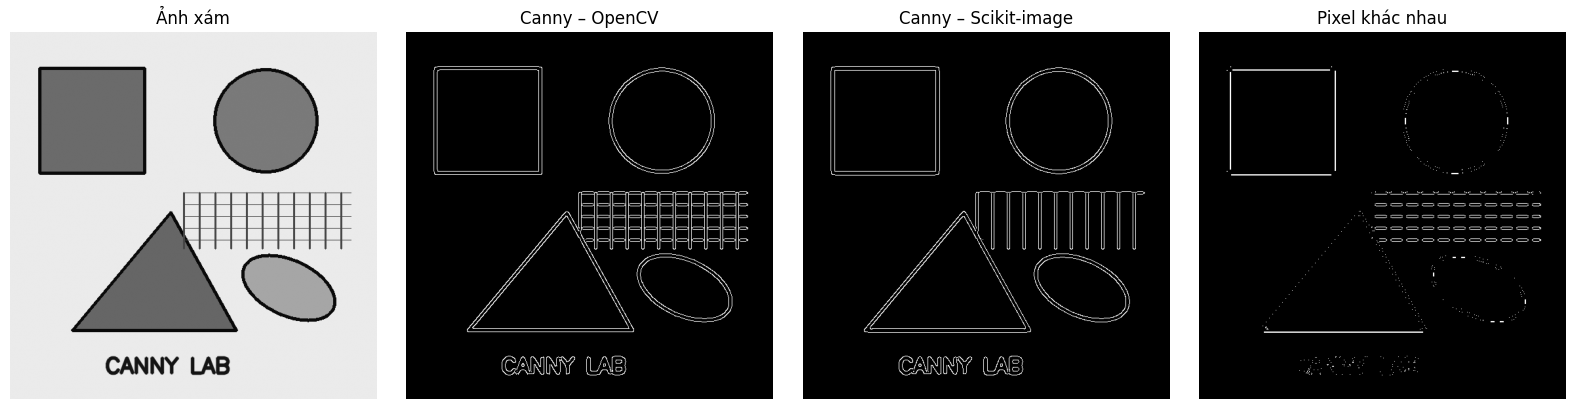

,Phương pháp,Thời gian (ms),Tỷ lệ pixel cạnh (%)
0,Canny – OpenCV,1.870,3.120
1,Canny – Scikit-image,167.207,2.494


In [ ]:
# OpenCV: Gaussian được thực hiện tường minh trước cv2.Canny.
SIGMA_COMPARE = 1.4
LOW_COMPARE, HIGH_COMPARE = 50, 150
blur_cv = cv2.GaussianBlur(gray, (5, 5), SIGMA_COMPARE)

t0 = time.perf_counter()
edges_cv = cv2.Canny(blur_cv, LOW_COMPARE, HIGH_COMPARE)
time_cv = (time.perf_counter() - t0) * 1000

# Scikit-image: feature.canny tự thực hiện Gaussian smoothing và NMS.
# Ảnh float được chuẩn hóa về [0, 1], do đó ngưỡng cũng chuyển sang thang [0, 1].
gray_float = gray.astype(np.float32) / 255.0

t0 = time.perf_counter()
edges_sk = feature.canny(
    gray_float,
    sigma=SIGMA_COMPARE,
    low_threshold=LOW_COMPARE / 255.0,
    high_threshold=HIGH_COMPARE / 255.0
)
time_sk = (time.perf_counter() - t0) * 1000
edges_sk_u8 = (edges_sk.astype(np.uint8) * 255)

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
items = [(gray, "Ảnh xám"), (edges_cv, "Canny – OpenCV"),
         (edges_sk_u8, "Canny – Scikit-image"),
         (cv2.absdiff(edges_cv, edges_sk_u8), "Pixel khác nhau")]
for ax, (im, title) in zip(axes, items):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
save_img("I1_canny_opencv.png", edges_cv)
save_img("I1_canny_skimage.png", edges_sk_u8)
save_img("I1_khac_biet_hai_thu_vien.png", cv2.absdiff(edges_cv, edges_sk_u8))

bang_so_sanh = pd.DataFrame([
    ["Canny – OpenCV", time_cv, edge_density(edges_cv)],
    ["Canny – Scikit-image", time_sk, edge_density(edges_sk_u8)]
], columns=["Phương pháp", "Thời gian (ms)", "Tỷ lệ pixel cạnh (%)"])
display(bang_so_sanh.round(3))


**Nhận xét cần ghi nhận:** hai thư viện đều triển khai Canny nhưng kết quả không nhất thiết trùng khít. Cách tính gradient, quy ước ngưỡng và chi tiết triển khai có thể khác nhau. Trong cell trên, ảnh đầu vào và sigma được giữ tương ứng; ngưỡng Scikit-image được chuẩn hóa theo ảnh float [0, 1]. Vì vậy đây là so sánh thực nghiệm gần tương đương, không phải khẳng định hai thuật toán có đầu ra pixel-identical.

### I.2. So sánh với Sobel và Laplacian

Sobel phát hiện biến thiên theo hai hướng X/Y; Laplacian sử dụng đạo hàm bậc hai; Canny kết hợp làm trơn, triệt cực đại không cục bộ và ngưỡng kép.

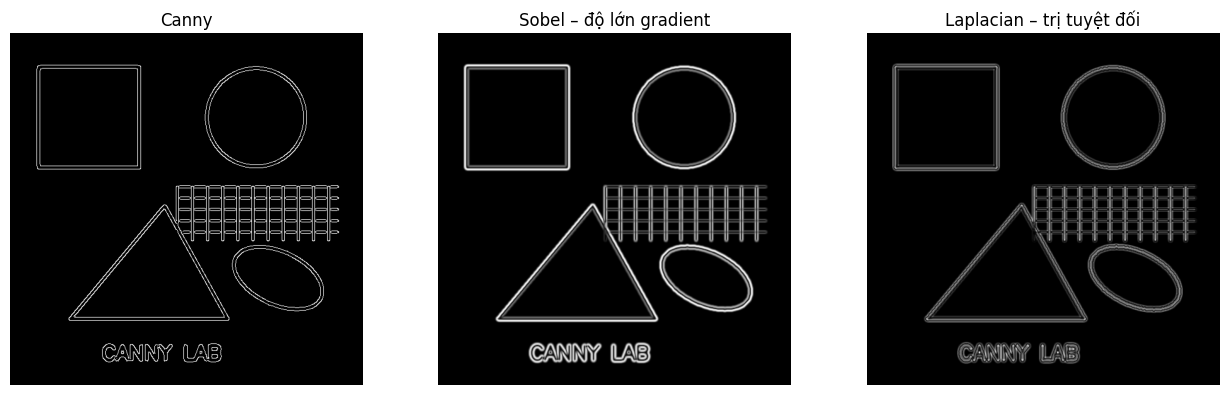

PosixPath('results/I2_laplacian.png')

In [ ]:
blur = cv2.GaussianBlur(gray, (5, 5), 1.4)

sobel_x = cv2.Sobel(blur, cv2.CV_32F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blur, cv2.CV_32F, 0, 1, ksize=3)
sobel_mag = cv2.magnitude(sobel_x, sobel_y)
sobel_img = cv2.normalize(sobel_mag, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

laplacian = cv2.Laplacian(blur, cv2.CV_32F, ksize=3)
laplacian_img = cv2.normalize(np.abs(laplacian), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, im, title in zip(axes, [edges_cv, sobel_img, laplacian_img],
                         ["Canny", "Sobel – độ lớn gradient", "Laplacian – trị tuyệt đối"]):
    ax.imshow(im, cmap="gray")
    ax.set_title(title)
    ax.axis("off")
plt.tight_layout()
plt.show()
save_img("I2_sobel.png", sobel_img)
save_img("I2_laplacian.png", laplacian_img)


**Kết luận:** Sobel ước lượng gradient theo từng hướng, Laplacian dựa trên đạo hàm bậc hai; ảnh kết quả dạng độ lớn thường còn nhiều mức xám và có thể tạo biên dày. Canny có thêm làm trơn, triệt cực đại không cục bộ và ngưỡng kép nên thường tạo đường biên mảnh, dễ kiểm soát hơn. Không nên kết luận thuật toán nào luôn chính xác/tốc độ hơn trong mọi trường hợp nếu chưa đo trên cùng dữ liệu và cấu hình.

# II. KHẢO SÁT THAM SỐ CANNY

Thay đổi sigma, ngưỡng thấp và ngưỡng cao; quan sát ảnh đầu ra, tỷ lệ pixel cạnh và so sánh với cấu hình mặc định.

### 5.1. Ảnh hưởng của sigma

Sigma điều khiển độ rộng Gaussian. Sigma nhỏ giữ lại nhiều chi tiết nhưng dễ giữ cả nhiễu; sigma lớn làm trơn mạnh hơn nhưng có thể làm mất cạnh nhỏ.

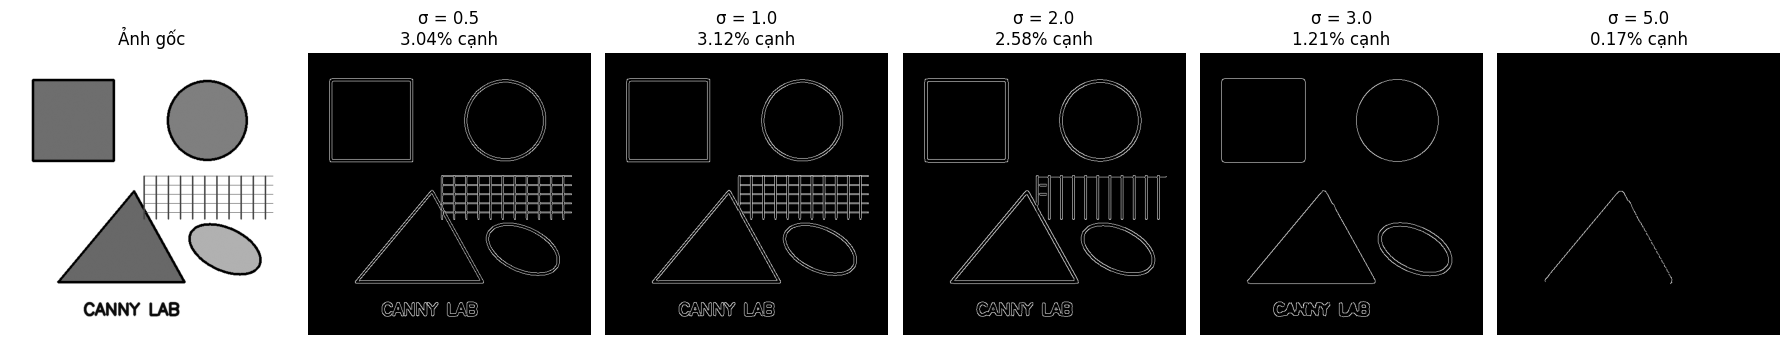

,Sigma,Tỷ lệ pixel cạnh (%)
0,0.5,3.043
1,1.0,3.118
2,2.0,2.580
3,3.0,1.207
4,5.0,0.168


In [ ]:
def canny_opencv_sigma(gray_img, sigma, low=50, high=150):
    if sigma > 0:
        ksize = max(3, int(6 * sigma + 1) | 1)  # kernel lẻ, xấp xỉ 6*sigma
        smoothed = cv2.GaussianBlur(gray_img, (ksize, ksize), sigma)
    else:
        smoothed = gray_img
    return cv2.Canny(smoothed, low, high)

sigmas = [0.5, 1.0, 2.0, 3.0, 5.0]
fig, axes = plt.subplots(1, len(sigmas) + 1, figsize=(18, 4))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Ảnh gốc"); axes[0].axis("off")
rows = []
for ax, sigma in zip(axes[1:], sigmas):
    edge = canny_opencv_sigma(gray, sigma, 50, 150)
    ratio = edge_density(edge)
    ax.imshow(edge, cmap="gray"); ax.set_title(f"σ = {sigma}\n{ratio:.2f}% cạnh"); ax.axis("off")
    rows.append([sigma, ratio])
plt.tight_layout(); plt.show()
for sigma in sigmas:
    save_img(f"II1_sigma_{str(sigma).replace('.', '_')}.png", canny_opencv_sigma(gray, sigma, 50, 150))
display(pd.DataFrame(rows, columns=["Sigma", "Tỷ lệ pixel cạnh (%)"]).round(3))


### 5.2. Ảnh hưởng của ngưỡng thấp và ngưỡng cao

Ngưỡng thấp giúp quyết định pixel yếu nào có thể được giữ lại khi liên kết với cạnh mạnh. Ngưỡng cao quyết định pixel nào được xem là cạnh mạnh. Thông thường ngưỡng cao lớn hơn ngưỡng thấp.

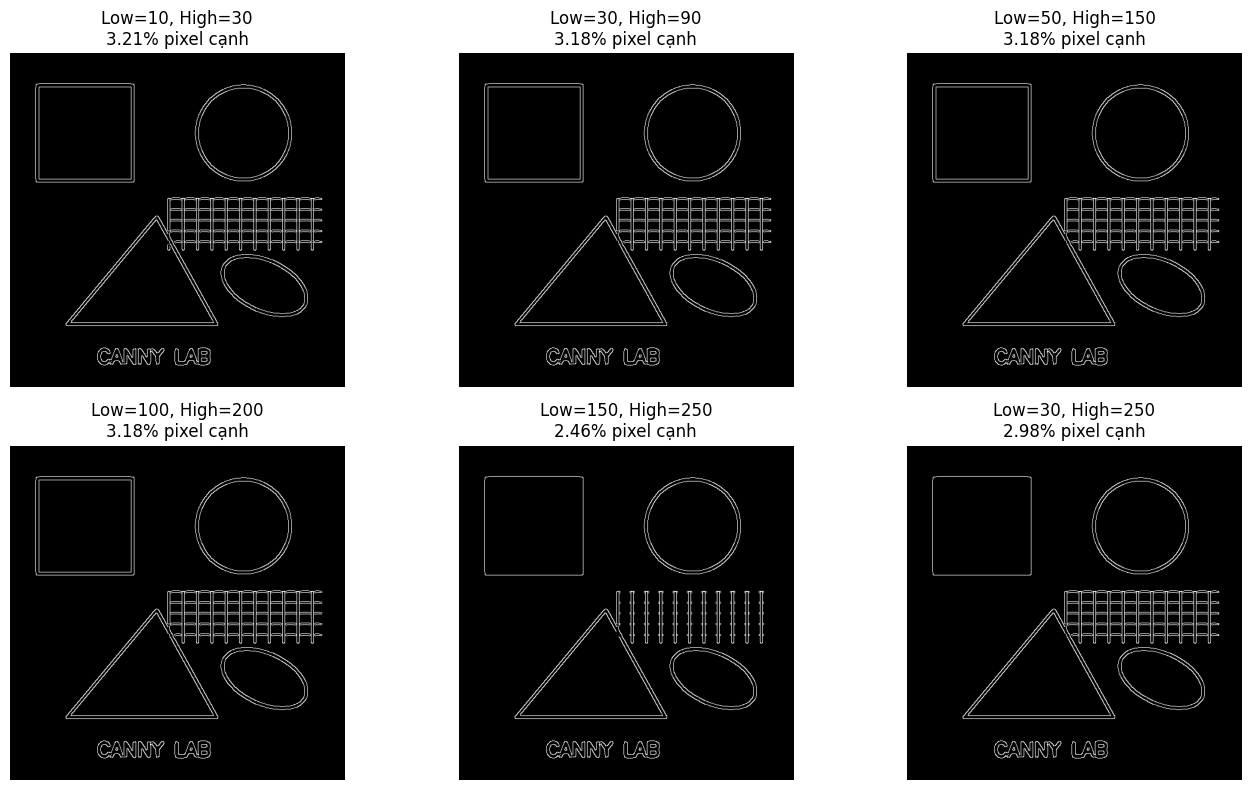

,Ngưỡng thấp,Ngưỡng cao,Tỷ lệ pixel cạnh (%)
0,10,30,3.214
1,30,90,3.181
2,50,150,3.180
3,100,200,3.178
4,150,250,2.464
5,30,250,2.983


In [ ]:
threshold_pairs = [(10, 30), (30, 90), (50, 150), (100, 200), (150, 250), (30, 250)]
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
rows = []
for ax, (low, high) in zip(axes.ravel(), threshold_pairs):
    edge = canny_opencv_sigma(gray, 1.4, low, high)
    ratio = edge_density(edge)
    ax.imshow(edge, cmap="gray")
    ax.set_title(f"Low={low}, High={high}\n{ratio:.2f}% pixel cạnh")
    ax.axis("off")
    rows.append([low, high, ratio])
plt.tight_layout(); plt.show()
for low, high in threshold_pairs:
    save_img(f"II2_threshold_{low}_{high}.png", canny_opencv_sigma(gray, 1.4, low, high))
display(pd.DataFrame(rows, columns=["Ngưỡng thấp", "Ngưỡng cao", "Tỷ lệ pixel cạnh (%)"]).round(3))


### 5.3. So sánh cấu hình mặc định và cấu hình tùy chỉnh

Lưu ý: mặc định của mỗi thư viện không hoàn toàn giống nhau. OpenCV yêu cầu ngưỡng đầu vào; Scikit-image có cấu hình mặc định riêng (sigma và ngưỡng tự động theo dữ liệu).

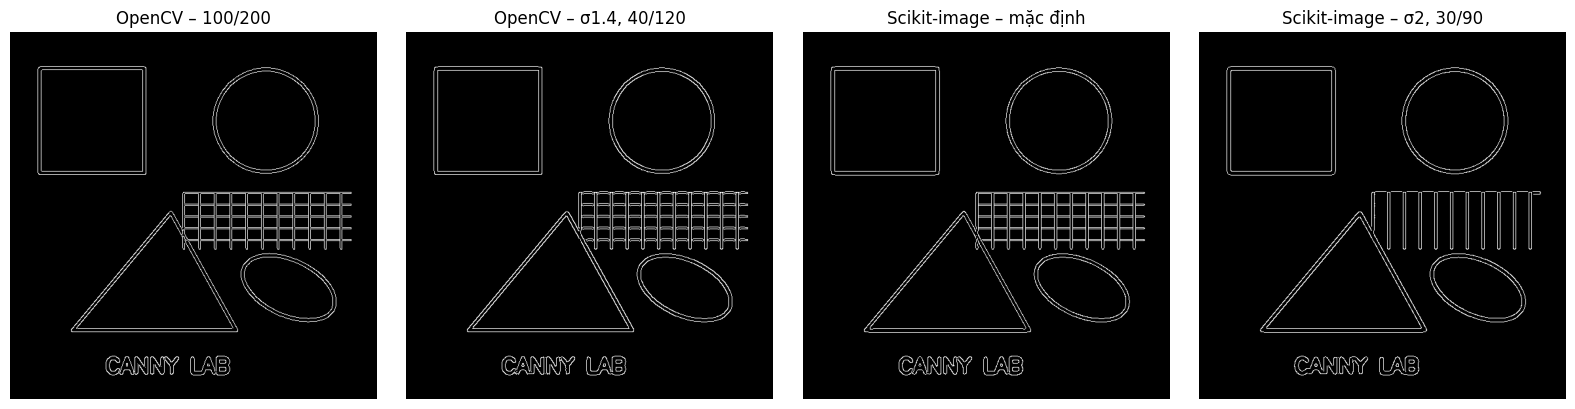

PosixPath('results/II3_skimage_tuy_chinh.png')

In [ ]:
# OpenCV mặc định thường dùng trong ví dụ: threshold 100/200, không Gaussian tường minh.
cv_default = cv2.Canny(gray, 100, 200)
# OpenCV cấu hình tùy chỉnh.
cv_custom = canny_opencv_sigma(gray, 1.4, 40, 120)
# Scikit-image mặc định.
sk_default = feature.canny(gray_float)
# Scikit-image tùy chỉnh.
sk_custom = feature.canny(gray_float, sigma=2.0,
                          low_threshold=30/255.0, high_threshold=90/255.0)

compare_items = [(cv_default, "OpenCV – 100/200"), (cv_custom, "OpenCV – σ1.4, 40/120"),
                 (sk_default, "Scikit-image – mặc định"), (sk_custom, "Scikit-image – σ2, 30/90")]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (edge, title) in zip(axes, compare_items):
    ax.imshow(edge, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("II3_opencv_mac_dinh.png", cv_default)
save_img("II3_opencv_tuy_chinh.png", cv_custom)
save_img("II3_skimage_mac_dinh.png", (sk_default.astype(np.uint8) * 255))
save_img("II3_skimage_tuy_chinh.png", (sk_custom.astype(np.uint8) * 255))


**Nhận xét:** sigma tăng thường làm giảm các chi tiết nhỏ và cạnh do nhiễu. Tăng cả hai ngưỡng thường làm giảm số pixel cạnh được giữ lại; ngưỡng quá cao có thể làm đứt hoặc mất cạnh yếu. Cấu hình tốt phụ thuộc nội dung, độ sáng, độ tương phản và mức nhiễu của ảnh.

# III. CANNY TRÊN CÁC LOẠI ẢNH

Thử nghiệm với ảnh nhiều nhiễu, ảnh tương phản thấp và ảnh nhiều chi tiết. Các biến thể được tạo từ cùng ảnh đầu vào để giữ điều kiện so sánh nhất quán.

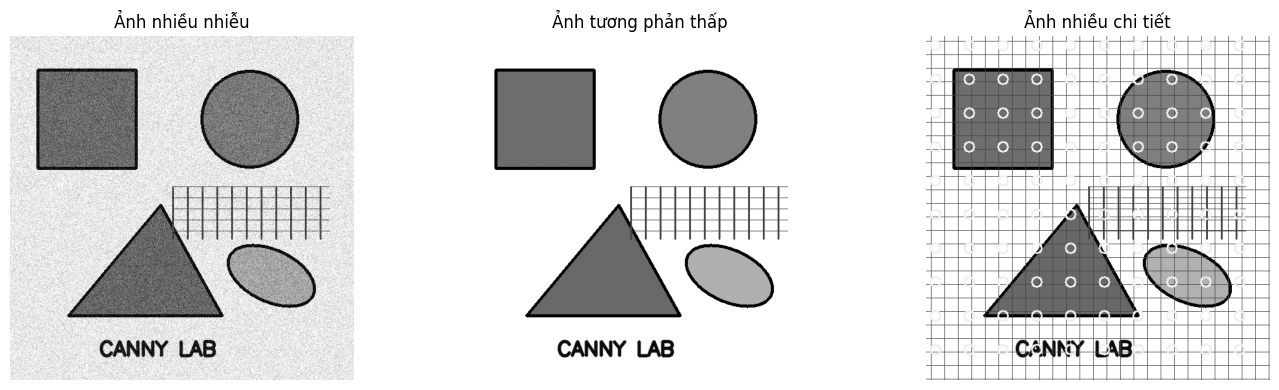

PosixPath('results/III0_nhieu_chi_tiet.png')

In [ ]:
rng = np.random.default_rng(42)

# Ảnh nhiều nhiễu: cộng nhiễu Gaussian.
noise = rng.normal(0, 24, gray.shape)
image_noisy = np.clip(gray.astype(np.float32) + noise, 0, 255).astype(np.uint8)

# Ảnh tương phản thấp: co dải cường độ quanh mức xám 128.
image_low_contrast = np.clip(128 + 0.30 * (gray.astype(np.float32) - 128), 0, 255).astype(np.uint8)

# Ảnh nhiều chi tiết: tạo lưới đường, vòng tròn và họa tiết nhỏ.
image_detailed = gray.copy()
H, W = image_detailed.shape
for x in range(8, W, 22): cv2.line(image_detailed, (x, 0), (x, H-1), 70, 1)
for y in range(8, H, 22): cv2.line(image_detailed, (0, y), (W-1, y), 70, 1)
for x in range(15, W, 55):
    for y in range(15, H, 55): cv2.circle(image_detailed, (x, y), 8, 220, 2)

image_cases = {
    "Ảnh nhiều nhiễu": image_noisy,
    "Ảnh tương phản thấp": image_low_contrast,
    "Ảnh nhiều chi tiết": image_detailed
}

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, im) in zip(axes, image_cases.items()):
    ax.imshow(im, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("III0_anh_nhieu.png", image_noisy)
save_img("III0_tuong_phan_thap.png", image_low_contrast)
save_img("III0_nhieu_chi_tiet.png", image_detailed)


### 6.1. So sánh Canny không làm trơn và có Gaussian + ngưỡng tự động

Ngưỡng tự động theo median trong code là một heuristic, không phải ngưỡng tối ưu cho mọi ảnh.

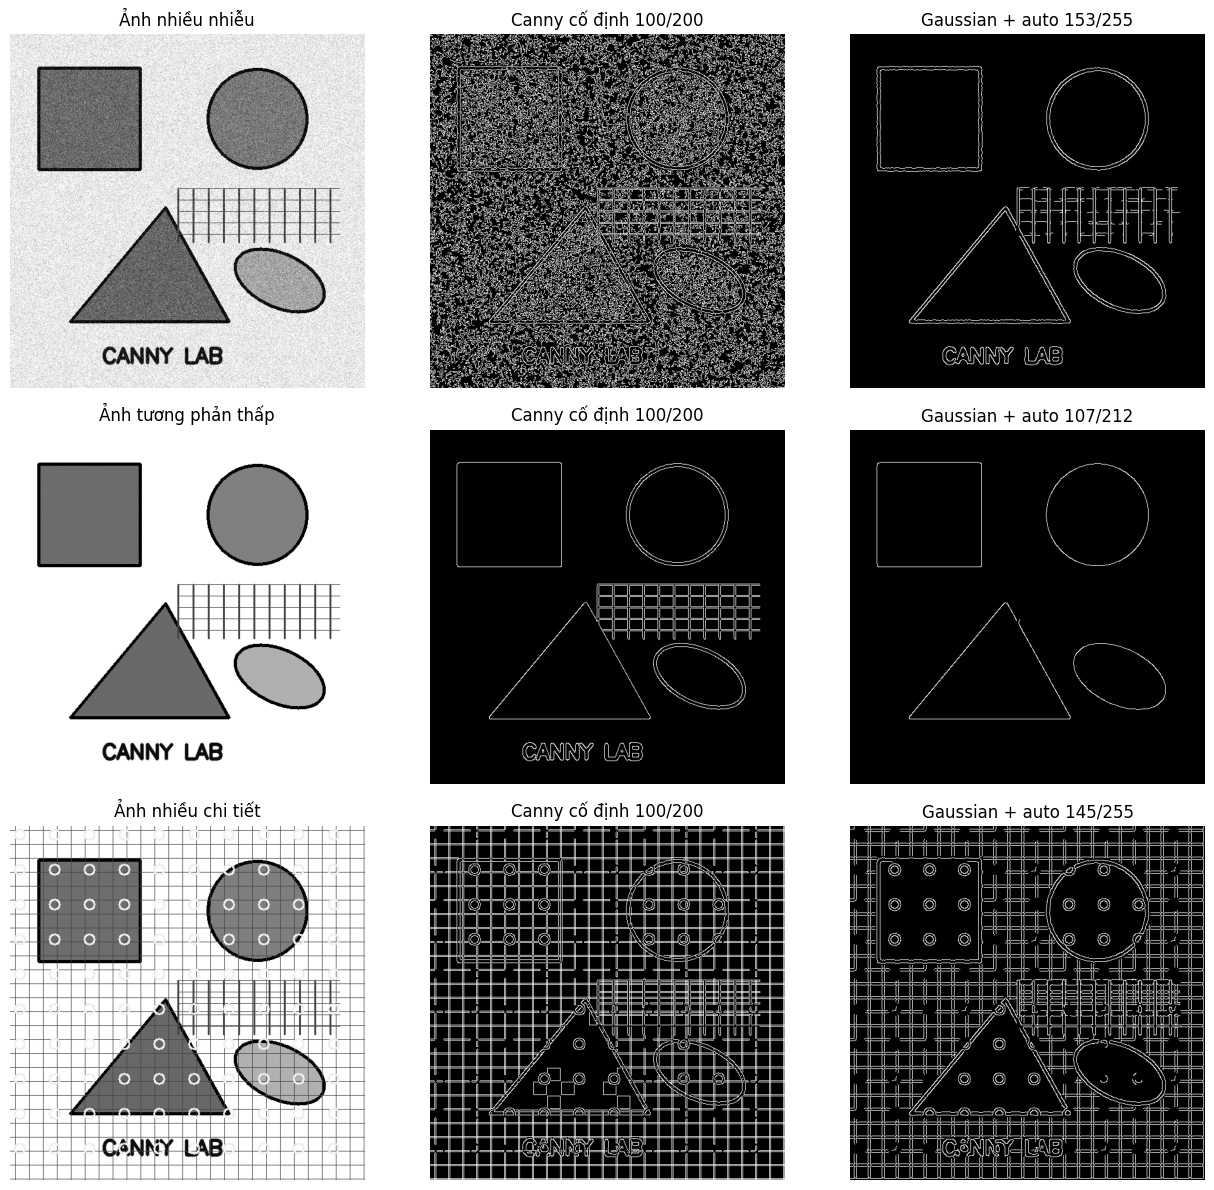

,Loại ảnh,Canny cố định (%),Gaussian + auto (%),Low auto,High auto
0,Ảnh nhiều nhiễu,27.378,2.822,153,255
1,Ảnh tương phản thấp,2.557,0.785,107,212
2,Ảnh nhiều chi tiết,17.940,13.263,145,255


In [ ]:
def canny_auto_median(gray_img, sigma_factor=0.33, blur_sigma=1.4):
    smooth = cv2.GaussianBlur(gray_img, (5, 5), blur_sigma)
    median = float(np.median(smooth))
    low = int(max(0, (1.0 - sigma_factor) * median))
    high = int(min(255, (1.0 + sigma_factor) * median))
    if high <= low: high = min(255, low + 1)
    return cv2.Canny(smooth, low, high), low, high

fig, axes = plt.subplots(3, 3, figsize=(13, 12))
summary = []
for row, (name, im) in enumerate(image_cases.items()):
    raw = cv2.Canny(im, 100, 200)
    auto, low, high = canny_auto_median(im)
    for ax, result, title in zip(axes[row], [im, raw, auto],
                                 [name, "Canny cố định 100/200", f"Gaussian + auto {low}/{high}"]):
        ax.imshow(result, cmap="gray"); ax.set_title(title); ax.axis("off")
    summary.append([name, edge_density(raw), edge_density(auto), low, high])
plt.tight_layout(); plt.show()
for case_name, case_img in image_cases.items():
    safe_name = case_name.lower().replace(" ", "_")
    save_img(f"III1_{safe_name}_canny_co_dinh.png", cv2.Canny(case_img, 100, 200))
    auto_edges, _, _ = canny_auto_median(case_img)
    save_img(f"III1_{safe_name}_gaussian_auto.png", auto_edges)
display(pd.DataFrame(summary, columns=["Loại ảnh", "Canny cố định (%)", "Gaussian + auto (%)", "Low auto", "High auto"]).round(3))


### 6.2. Đánh giá và kết luận

- **Ảnh nhiều nhiễu:** thường xuất hiện nhiều cạnh giả nếu xử lý trực tiếp; Gaussian trước Canny giúp giảm nhiễu nhưng sigma quá lớn có thể xóa cạnh nhỏ.
- **Ảnh tương phản thấp:** gradient yếu nên ngưỡng cố định có thể bỏ sót cạnh; cần thử ngưỡng thấp hơn hoặc phương pháp tự động, đồng thời kiểm tra nguy cơ tăng cạnh giả.
- **Ảnh nhiều chi tiết:** có thể tạo mật độ cạnh cao; tăng sigma/ngưỡng có thể giảm chi tiết không cần thiết nhưng cũng có thể làm mất cấu trúc nhỏ.

Tỷ lệ pixel cạnh chỉ phản ánh mật độ cạnh, **không đồng nghĩa với độ chính xác**. Muốn đánh giá định lượng chất lượng thực sự cần ảnh cạnh chuẩn (ground truth) được gán nhãn.

# IV. KẾT HỢP CANNY VỚI PHÂN ĐOẠN VÀ NHẬN DẠNG

Dùng morphology để nối các đoạn biên, contour để tách vùng, `approxPolyDP` để phân loại hình dạng và Hough Circle để tìm đường tròn.

Số vùng contour sau lọc diện tích: 4


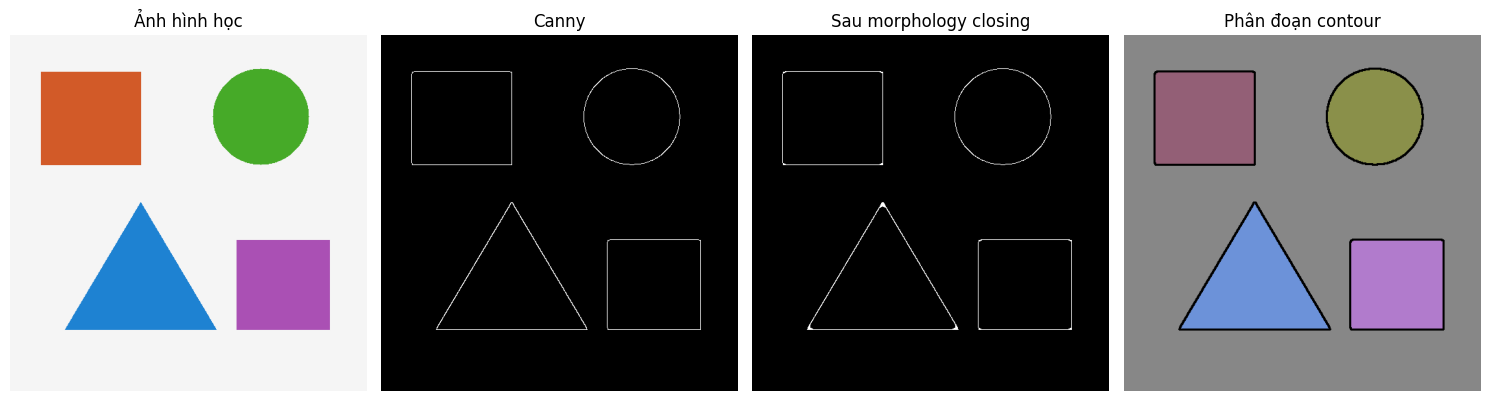

PosixPath('results/IV1_phan_doan_contour.png')

In [ ]:
def tao_anh_hinh_hoc(size=520):
    canvas = np.full((size, size, 3), 245, np.uint8)
    cv2.rectangle(canvas, (45, 55), (190, 190), (40, 90, 210), -1)
    cv2.circle(canvas, (365, 120), 70, (40, 170, 70), -1)
    pts = np.array([[80, 430], [190, 245], [300, 430]], np.int32)
    cv2.fillPoly(canvas, [pts], (210, 130, 30))
    cv2.rectangle(canvas, (330, 300), (465, 430), (180, 80, 170), -1)
    return canvas

shape_bgr = tao_anh_hinh_hoc()
shape_gray = cv2.cvtColor(shape_bgr, cv2.COLOR_BGR2GRAY)
shape_blur = cv2.GaussianBlur(shape_gray, (5, 5), 1.4)
shape_edges = cv2.Canny(shape_blur, 40, 120)

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
shape_closed = cv2.morphologyEx(shape_edges, cv2.MORPH_CLOSE, kernel, iterations=2)
contours, _ = cv2.findContours(shape_closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
min_area = 0.002 * shape_gray.size
contours = [c for c in contours if cv2.contourArea(c) > min_area]

segmentation = np.zeros_like(shape_bgr)
rng = np.random.default_rng(7)
for contour in contours:
    color = tuple(int(v) for v in rng.integers(60, 245, size=3))
    cv2.drawContours(segmentation, [contour], -1, color, thickness=cv2.FILLED)
overlay = cv2.addWeighted(shape_bgr, 0.55, segmentation, 0.45, 0)
cv2.drawContours(overlay, contours, -1, (0, 0, 0), 2)
print(f"Số vùng contour sau lọc diện tích: {len(contours)}")

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, im, title in zip(axes, [shape_bgr, shape_edges, shape_closed, overlay],
                         ["Ảnh hình học", "Canny", "Sau morphology closing", "Phân đoạn contour"]):
    ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB) if im.ndim == 3 else im, cmap=None if im.ndim == 3 else "gray")
    ax.set_title(title); ax.axis("off")
plt.tight_layout(); plt.show()
save_img("IV1_anh_hinh_hoc.png", shape_bgr)
save_img("IV1_canny.png", shape_edges)
save_img("IV1_morphology_closing.png", shape_closed)
save_img("IV1_phan_doan_contour.png", overlay)


### 7.1. Nhận dạng hình dạng bằng contour

`approxPolyDP` xấp xỉ đường bao thành đa giác. Số đỉnh và độ tròn (circularity) được dùng làm đặc trưng đơn giản để gán nhãn.

,Nhãn dự đoán,Diện tích,Số đỉnh xấp xỉ,Circularity
0,Hình vuông,17805.0,4,0.792
1,Tam giác,20637.0,3,0.557
2,Hình vuông,19845.0,4,0.791
3,Hình tròn,15414.0,8,0.900


Thống kê hình dạng: {'Hình vuông': 2, 'Tam giác': 1, 'Hình tròn': 1}


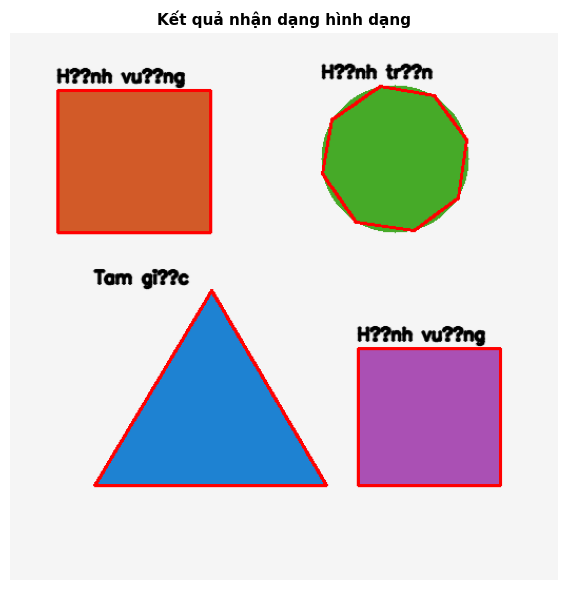

PosixPath('results/IV2_nhan_dang_hinh_dang.png')

In [ ]:
shape_result = shape_bgr.copy()
shape_counts = {}
shape_details = []

for contour in contours:
    perimeter = cv2.arcLength(contour, True)
    if perimeter <= 0: continue
    approx = cv2.approxPolyDP(contour, 0.03 * perimeter, True)
    vertices = len(approx)
    area = cv2.contourArea(contour)
    circularity = 4 * np.pi * area / (perimeter * perimeter + 1e-9)

    if vertices == 3:
        label = "Tam giác"
    elif vertices == 4:
        x, y, w, h = cv2.boundingRect(approx)
        label = "Hình vuông" if 0.90 <= w / max(h, 1) <= 1.10 else "Chữ nhật"
    elif circularity > 0.80:
        label = "Hình tròn"
    elif vertices > 4:
        label = f"Đa giác ({vertices} đỉnh)"
    else:
        label = "Khác"

    shape_counts[label] = shape_counts.get(label, 0) + 1
    x, y, w, h = cv2.boundingRect(contour)
    cv2.drawContours(shape_result, [approx], -1, (0, 0, 255), 2)
    cv2.putText(shape_result, label, (x, max(20, y - 7)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 2, cv2.LINE_AA)
    shape_details.append([label, round(area, 1), vertices, round(circularity, 3)])

display(pd.DataFrame(shape_details, columns=["Nhãn dự đoán", "Diện tích", "Số đỉnh xấp xỉ", "Circularity"]))
print("Thống kê hình dạng:", shape_counts)
show_grid([("Kết quả nhận dạng hình dạng", shape_result)], cols=1, figsize=(7, 6))
save_img("IV2_nhan_dang_hinh_dang.png", shape_result)


### 7.2. Phát hiện hình tròn bằng Hough Circle

Hough Circle là bước bổ sung để tìm đường tròn; thuật toán nhận ảnh xám đã làm trơn và tham số `param1` liên quan đến ngưỡng cao trong bộ phát hiện cạnh nội bộ của Hough.

Số hình tròn phát hiện bằng Hough: 1


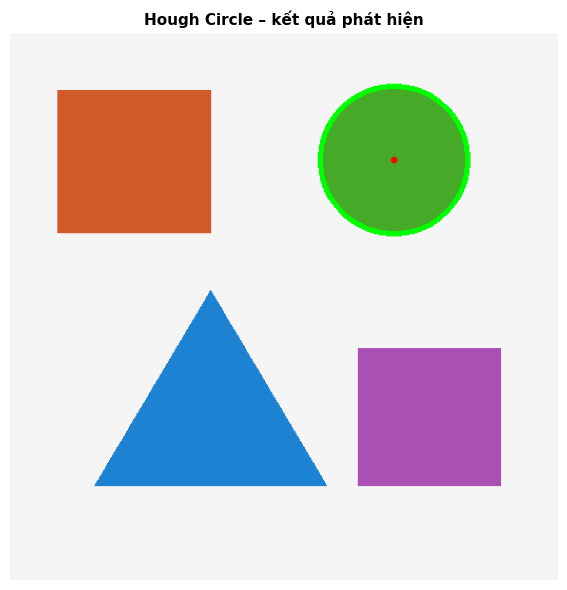

PosixPath('results/IV3_hough_circle.png')

In [ ]:
circles = cv2.HoughCircles(
    shape_blur, cv2.HOUGH_GRADIENT,
    dp=1.2, minDist=50,
    param1=120, param2=30,
    minRadius=20, maxRadius=120
)
hough_result = shape_bgr.copy()
if circles is not None:
    circles = np.round(circles[0]).astype(int)
    for x, y, radius in circles:
        cv2.circle(hough_result, (x, y), radius, (0, 255, 0), 3)
        cv2.circle(hough_result, (x, y), 3, (0, 0, 255), -1)
    print("Số hình tròn phát hiện bằng Hough:", len(circles))
else:
    print("Không phát hiện hình tròn. Có thể cần điều chỉnh param2/minDist/radius.")
show_grid([("Hough Circle – kết quả phát hiện", hough_result)], cols=1, figsize=(7, 6))
save_img("IV3_hough_circle.png", hough_result)


**Lưu ý về giới hạn:** phân đoạn contour từ Canny hoạt động tốt hơn khi biên khép kín và ít nhiễu. Nếu biên bị hở, contour có thể gộp vùng hoặc không bao quanh đúng đối tượng. Nhận dạng hình dạng bằng số đỉnh/circularity chỉ là phương pháp hình học cơ bản, có thể sai với vật thể méo, bị che khuất hoặc ảnh phối cảnh.

## 5. Kiểm tra và tổng kết kết quả

Tổng hợp các chỉ số chính và kiểm tra các file đầu ra trong `results/`.

In [ ]:
# Tạo bảng tổng hợp các chỉ số quan sát được trong notebook.
final_summary = pd.DataFrame([
    ["OpenCV Canny", time_cv, edge_density(edges_cv)],
    ["Scikit-image Canny", time_sk, edge_density(edges_sk_u8)],
    ["OpenCV – mặc định 100/200", np.nan, edge_density(cv_default)],
    ["OpenCV – tùy chỉnh σ1.4, 40/120", np.nan, edge_density(cv_custom)],
    ["Scikit-image – mặc định", np.nan, edge_density(sk_default)],
    ["Scikit-image – tùy chỉnh", np.nan, edge_density(sk_custom)]
], columns=["Phương pháp", "Thời gian đo ở Bài 1 (ms)", "Tỷ lệ pixel cạnh (%)"])
display(final_summary.round(3))

csv_path = OUTPUT_DIR / "lab3_canny_tong_hop.csv"
final_summary.to_csv(csv_path, index=False, encoding="utf-8-sig")
print("Đã lưu bảng tổng hợp:", csv_path)


,Phương pháp,Thời gian đo ở Bài 1 (ms),Tỷ lệ pixel cạnh (%)
0,OpenCV Canny,1.870,3.120
1,Scikit-image Canny,167.207,2.494
2,OpenCV – mặc định 100/200,NaN,3.024
3,"OpenCV – tùy chỉnh σ1.4, 40/120",NaN,3.181
4,Scikit-image – mặc định,NaN,3.060
5,Scikit-image – tùy chỉnh,NaN,2.505


Đã lưu bảng tổng hợp: results/lab3_canny_tong_hop.csv
